In [2]:
import numpy as np

In [3]:
import pandas as pd

In [4]:
df=pd.read_excel("Online Retail.xlsx", nrows=5000)

In [5]:
print("first 5 records")
df.head()

first 5 records


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
print("rows and columns")
display(df.shape)
print("The name of columns")
display(df.columns)

rows and columns


(5000, 8)

The name of columns


Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [7]:
print("Missing values")
display(df.isnull().sum)

Missing values


<bound method DataFrame.sum of       InvoiceNo  StockCode  Description  Quantity  InvoiceDate  UnitPrice  \
0         False      False        False     False        False      False   
1         False      False        False     False        False      False   
2         False      False        False     False        False      False   
3         False      False        False     False        False      False   
4         False      False        False     False        False      False   
...         ...        ...          ...       ...          ...        ...   
4995      False      False        False     False        False      False   
4996      False      False        False     False        False      False   
4997      False      False        False     False        False      False   
4998      False      False        False     False        False      False   
4999      False      False        False     False        False      False   

      CustomerID  Country  
0          False

In [8]:
print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())


Duplicate records:
79

Statistical summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,5000.000000,5000,5000.000000,3795.000000
mean,9.185800,2010-12-01 22:54:10.812000,3.792314,15906.281950
min,-9360.000000,2010-12-01 08:26:00,0.000000,12431.000000
25%,1.000000,2010-12-01 13:24:00,1.250000,14606.000000
50%,3.000000,2010-12-01 17:06:00,2.510000,15862.000000
75%,10.000000,2010-12-02 12:10:00,4.210000,17841.000000
max,2880.000000,2010-12-02 18:08:00,607.490000,18239.000000
std,144.940788,NaN,13.211720,1732.068892


In [9]:
missing = df.isnull().sum()

print("Missing values in each column:")
print(missing)

Missing values in each column:
InvoiceNo         0
StockCode         0
Description      12
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     1205
Country           0
dtype: int64


In [10]:
print("Dataset shape before cleaning:", df.shape)

# Remove rows where essential product description is missing
df = df.dropna(subset=["Description"])

print("Dataset shape after cleaning:", df.shape)

print("\nRemaining missing values:")
print(df.isnull().sum())

Dataset shape before cleaning: (5000, 8)
Dataset shape after cleaning: (4988, 8)

Remaining missing values:
InvoiceNo         0
StockCode         0
Description       0
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     1193
Country           0
dtype: int64


In [11]:
print("duplicate before cleaning ",df.duplicated().sum)
df=df.drop_duplicates()
print("duplicates after cleaning",df.duplicated().sum)
print("Dataset shape after removing duplicates:", df.shape)

duplicate before cleaning  <bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
4995    False
4996    False
4997    False
4998    False
4999    False
Length: 4988, dtype: bool>
duplicates after cleaning <bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
4995    False
4996    False
4997    False
4998    False
4999    False
Length: 4909, dtype: bool>
Dataset shape after removing duplicates: (4909, 8)


In [12]:
# negative quantities and zero quantities
print("negative quantities",(df["Quantity"]<0).sum())
print("zero quantities",(df["Quantity"]==0).sum())
# negative price and zero price
print("negative price",(df["UnitPrice"]<0).sum())
print("zero price",(df["UnitPrice"]==0).sum())

negative quantities 70
zero quantities 0
negative price 0
zero price 0


In [13]:
# Keep records with positive quantities and prices
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

print("Original cleaned dataset:", df.shape)
print("Positive-sales dataset:", sales_df.shape)

Original cleaned dataset: (4909, 8)
Positive-sales dataset: (4839, 8)


In [14]:
import matplotlib.pyplot as plt

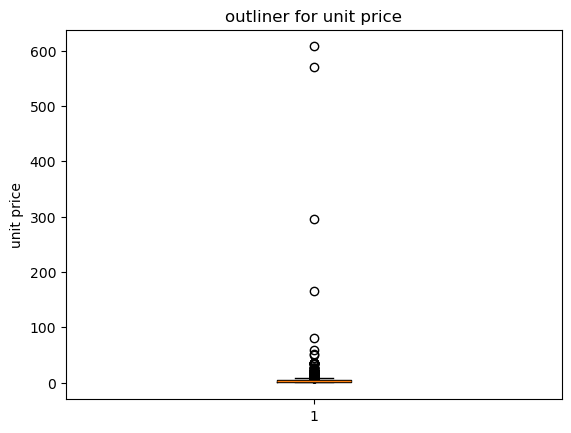

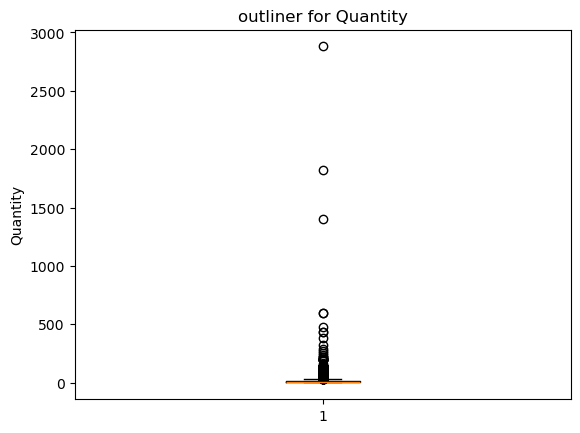

In [15]:
plt.boxplot(sales_df["UnitPrice"])
plt.title("outliner for unit price")
plt.ylabel("unit price")
plt.show()
# Quantity
plt.boxplot(sales_df["Quantity"])
plt.title("outliner for Quantity")
plt.ylabel("Quantity")
plt.show()

In [16]:
Q1 = sales_df["UnitPrice"].quantile(0.25)
Q3 = sales_df["UnitPrice"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = sales_df[
    (sales_df["UnitPrice"] < lower_limit) |
    (sales_df["UnitPrice"] > upper_limit)
]

print("Potential price outliers:", len(outliers))

Lower limit: -3.1899999999999995
Upper limit: 8.649999999999999
Potential price outliers: 299


In [17]:
# Remove extra spaces from product descriptions
sales_df["Description"] = (
    sales_df["Description"].astype("string").str.strip()
)

# Convert InvoiceDate into date-time format
sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"], errors="coerce"
)

# Check data types
print(sales_df.dtypes)


InvoiceNo              object
StockCode              object
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [18]:
sales_df["SalesAmount"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

print(sales_df[
    ["Description", "Quantity", "UnitPrice", "SalesAmount"]
].head())

                           Description  Quantity  UnitPrice  SalesAmount
0   WHITE HANGING HEART T-LIGHT HOLDER         6       2.55        15.30
1                  WHITE METAL LANTERN         6       3.39        20.34
2       CREAM CUPID HEARTS COAT HANGER         8       2.75        22.00
3  KNITTED UNION FLAG HOT WATER BOTTLE         6       3.39        20.34
4       RED WOOLLY HOTTIE WHITE HEART.         6       3.39        20.34


In [19]:
sales_df.to_csv("Beauty_Wellness_Cleaned_Data.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", sales_df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (4839, 9)


In [20]:
print("Missing values:")
print(sales_df.isnull().sum())

print("\nDuplicate rows:", sales_df.duplicated().sum())

print("\nFinal dataset preview:")
display(sales_df.head())

Missing values:
InvoiceNo         0
StockCode         0
Description       0
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     1193
Country           0
SalesAmount       0
dtype: int64

Duplicate rows: 0

Final dataset preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [21]:
print("Final Dataset Shape:", sales_df.shape)

print("\nMissing Values:")
print(sales_df.isnull().sum())

print("\nDuplicate Records:")
print(sales_df.duplicated().sum())

print("\nFirst 5 Cleaned Records:")
display(sales_df.head())

print("\nSales Amount Summary:")
print(sales_df["SalesAmount"].describe())

Final Dataset Shape: (4839, 9)

Missing Values:
InvoiceNo         0
StockCode         0
Description       0
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     1193
Country           0
SalesAmount       0
dtype: int64

Duplicate Records:
0

First 5 Cleaned Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34



Sales Amount Summary:
count    4839.000000
mean       21.443213
std        62.849136
min         0.290000
25%         4.210000
50%        10.500000
75%        17.850000
max      1627.200000
Name: SalesAmount, dtype: float64
